# Chapter 31: Matching, Assignment, and Exchange Design

This notebook reruns four worked examples from the chapter: early offers before a fit signal (unraveling), ranking strategy under the Boston mechanism, the gain from a thick market, and congestion in applications. All examples are hypothetical, as in the book; a few extra input values are added.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def vline(ax, x, text=None, col="grey", style="dashed", y_frac=0.95, ha="left", lw=1.4):
    """Vertical reference line with an optional label near the top of the axes."""
    ax.axvline(x, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x, y_frac), xycoords=("data", "axes fraction"), xytext=(5 if ha == "left" else -5, 0),
                    textcoords="offset points", ha=ha, va="top", color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def pct(fraction, digits=1):
    """Percent from a fraction: pct(0.022) -> '2.2%'."""
    return f"{num(100 * float(fraction), digits)}%"


def tie_or_winner(a_name, a_value, b_name, b_value, tol=1e-9, higher_wins=True):
    """Return (winner or 'tie', is_tie). Ties within ``tol`` are reported honestly."""
    if abs(float(a_value) - float(b_value)) <= tol:
        return "tie", True
    a_better = a_value > b_value if higher_wins else a_value < b_value
    return (a_name if a_better else b_name), False


def match_surplus(assignment, values):
    """Total surplus of an assignment: sum of values[(a, b)] over the matched pairs.

    Principles: market-unraveling, market-thickness. Book (ch031): pooled C-A, L-B gives 110 + 95 = 205;
    crossed C-B, L-A gives 65 + 75 = 140; waiting with the fit signal gives 110 + 110 = 220.
    """
    return sum(values[pair] for pair in assignment)


def boston_report_value(q, v_top, v_safe):
    """Expected value of listing the contested favorite first versus the guaranteed safe school.

    Principle: boston-mechanism-priority-loss. Listing the top first pays (1 - q) v_top; listing the safe
    school first pays v_safe. Book (ch031): q = 0.40 gives (1 - 0.40)(120) = 72 < 85; q = 0.20 gives 96 > 85.
    The indifference probability is 1 - v_safe / v_top (book values: 0.292).
    """
    top = (1 - q) * v_top
    if abs(top - v_safe) <= 1e-9:
        best = "tie"
    else:
        best = "top first" if top > v_safe else "safe first"
    return {"top_first": top, "safe_first": v_safe, "best": best, "q_indifferent": 1 - v_safe / v_top}


def congestion_review_prob(grads, apps, firms, capacity, suitable):
    """Random-screening review probability and the chance at least one suitable application is reviewed.

    Principle: market-congestion. Book (ch031): 120 graduates x 12 applications = 1,440; load 1,440 / 12 = 120
    per firm; rho = 40 / 120 = 1/3; 480 reviews and 960 unreviewed; 1 - (1 - 1/3)^2 = 5/9 = 55.56%. A cap of 4
    applications or capacity 150 makes rho = 1.
    """
    total = grads * apps
    load = total / firms
    rho = min(1.0, capacity / load) if load > 0 else 1.0
    reviews = min(total, firms * capacity)
    return {"total": total, "load": load, "rho": rho, "reviews": reviews, "unreviewed": total - reviews,
            "p_any": 1 - (1 - rho) ** suitable}


plt.rcParams.update(HOUSE_RC)


auctions = SimpleNamespace(match_surplus=match_surplus, boston_report_value=boston_report_value, congestion_review_prob=congestion_review_prob)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'market-unraveling': {'high': 110,
                       'low': 55,
                       'wait_total': 220,
                       'early_pair': 82.5,
                       'early_total': 165,
                       'loss': 55,
                       'waiting_cost': 70,
                       'wait_net': 150},
 'boston-mechanism-priority-loss': {'v_top': 120,
                                    'v_safe': 85,
                                    'q': 0.4,
                                    'top_first': 72,
                                    'q_alt': 0.2,
                                    'top_first_alt': 96},
 'market-thickness': {'values': {'CA': 110, 'CB': 65, 'LA': 75, 'LB': 95},
                      'pooled': 205,
                      'fragmented': 140,
                      'gain': 65,
                      'option_losses': [35, 30],
                      'cost_each': 18,
                      'participants': 4,
                      'pooled_net': 133},
 'market-congestion': {'grads': 120,
                       'apps': 12,
                       'firms': 12,
                       'capacity': 40,
                       'suitable': 2,
                       'total': 1440,
                       'load': 120,
                       'rho': 0.3333333333333333,
                       'reviews': 480,
                       'unreviewed': 960,
                       'p_any': 0.5555555555555556,
                       'p_any_pct_2dp': 55.56,
                       'cap_apps': 4,
                       'capacity_alt': 150},
 'constructed': {'market-unraveling': {'waiting_cost': [40]},
                 'boston-mechanism-priority-loss': {'q': [0.3, 0.6]},
                 'market-thickness': {'cost_each': [10]},
                 'market-congestion': {'apps': [8], 'capacity': [80]}}}


THICK = {("C", "A"): 110, ("C", "B"): 65, ("L", "A"): 75, ("L", "B"): 95}


def _two_bars(ax, names, vals, cols, ylabel, xlabel, ymax):
    xs = np.arange(len(vals))
    ax.bar(xs, vals, color=cols, width=0.55)
    for x, v in zip(xs, vals):
        label(ax, x, v, num(v, 1 if v % 1 else 0), dx=0, dy=3, ha="center")
    ax.set_xticks(xs, names)
    ax.set_ylim(0, ymax)
    ax.set_ylabel(ylabel)
    ax.set_xlabel(xlabel)


def unravel_picture(w=0):
    wait = auctions.match_surplus([("N", "P"), ("S", "Q")], {("N", "P"): 110, ("S", "Q"): 110})
    pair = (110 + 55) / 2
    early = pair + pair
    net = wait - w
    fig, ax = new_figure()
    winner, tie = tie_or_winner("waiting", net, "early commitment", early)
    cols = [PALETTE["gold"] if winner == "waiting" or tie else PALETTE["grey"],
            PALETTE["gold"] if winner == "early commitment" or tie else PALETTE["grey"]]
    _two_bars(ax, ["Wait for the signal (net)", "Commit early"], [net, early], cols, "Expected total surplus",
              "Arrangement", 260)
    if w:
        ax.bar([0], [w], bottom=[net], color=PALETTE["terracotta"], alpha=0.3, width=0.55, label=f"waiting cost {w}")
        ax.legend(loc="upper right", frameon=False)
    verdict = ("The two arrangements tie." if tie else
               f"Waiting wins by {num(net - early, 1)}." if winner == "waiting" else
               f"Early commitment wins by {num(early - net, 1)}: it is efficient under this cost.")
    metrics = {"Waiting total": num(wait, 0), "Waiting net of cost": num(net, 0), "Early total": num(early, 0),
               "Information loss": num(wait - early, 0), "More surplus": "tie" if tie else winner}
    interp = (f"Waiting picks the high-fit pairs: 110 + 110 = {num(wait, 0)}, net {num(wait, 0)} - {w} = {num(net, 0)}. "
              f"Early commitment fixes pairs worth (110 + 55)/2 = 82.5 each: 82.5 + 82.5 = {num(early, 0)}. {verdict} "
              f"Waiting costs above 220 - 165 = 55 make early commitment efficient.")
    steps = [f"Waiting = 110 + 110 = {num(wait, 0)}", f"Net = {num(wait, 0)} - {w} = {num(net, 0)}",
             "Early pair = (110 + 55)/2 = 82.5", f"Early = 82.5 + 82.5 = {num(early, 0)}",
             f"Information loss = {num(wait, 0)} - {num(early, 0)} = {num(wait - early, 0)}"]
    alt = f"Two bars: waiting net {num(net, 0)} and early commitment {num(early, 0)}, with waiting cost {w}."
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def boston_picture(q=0.40):
    res = auctions.boston_report_value(q, 120, 85)
    qs = np.linspace(0, 1, 200)
    fig, ax = new_figure()
    ax.plot(qs, (1 - qs) * 120, color=PALETTE["navy"], linewidth=2.2, label="list P first: (1 - q) x 120")
    ax.axhline(85, color=PALETTE["gold"], linewidth=2.2, label="list S first: 85")
    vline(ax, res["q_indifferent"], f"indifferent q = {num(res['q_indifferent'], 3)}", col="grey", y_frac=0.1)
    mark(ax, q, res["top_first"], f"{num(res['top_first'], 0)}", col="navy", dx=8, dy=6)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 135)
    ax.legend(loc="upper right", frameon=False)
    ax.set_xlabel("Probability Zara applies to P")
    ax.set_ylabel("Nia's expected payoff")
    best = {"top first": "P first (truthful)", "safe first": "S first (demote favorite)", "tie": "tie"}[res["best"]]
    cmp = ">" if res["top_first"] > 85 else ("<" if res["top_first"] < 85 else "=")
    metrics = {"List P first": num(res["top_first"], 0), "List S first": "85", "Best report": best,
               "Indifference probability": num(res["q_indifferent"], 3)}
    interp = (f"Listing P first pays (1 - {num(q, 2)})(120) = {num(res['top_first'], 0)}; listing S first pays 85 for "
              f"sure. Since {num(res['top_first'], 0)} {cmp} 85, Nia's best report is {best}. She is indifferent at "
              f"q = 1 - 85/120 = {num(res['q_indifferent'], 3)}.")
    steps = [f"P first = (1 - {num(q, 2)})(120) = {num(res['top_first'], 0)}", "S first = 85",
             f"{num(res['top_first'], 0)} {cmp} 85: {best}", f"Indifference q = 1 - 85/120 = {num(res['q_indifferent'], 3)}"]
    alt = (f"Line of the payoff from listing P first falling with q against a flat 85; at q = {num(q, 2)} it is "
           f"{num(res['top_first'], 0)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def thick_picture(w=0):
    pooled = auctions.match_surplus([("C", "A"), ("L", "B")], THICK)
    frag = auctions.match_surplus([("C", "B"), ("L", "A")], THICK)
    net = pooled - 4 * w
    fig, (ax1, ax2) = new_figure(ncols=2)
    grid = np.array([[110, 65], [75, 95]])
    ax1.imshow(grid, cmap="Blues", vmin=0, vmax=160)
    for i in range(2):
        for j in range(2):
            ax1.text(j, i, str(grid[i, j]), ha="center", va="center", fontsize=12,
                     fontweight="bold" if (i, j) in [(0, 0), (1, 1)] else "normal")
    ax1.set_xticks([0, 1], ["Aria", "Bo"])
    ax1.set_yticks([0, 1], ["Clinic", "Lab"])
    ax1.set_xlabel("Analyst")
    ax1.set_ylabel("Employer")
    winner, tie = tie_or_winner("pooling", net, "fragmented", frag)
    cols = [PALETTE["gold"] if winner == "pooling" or tie else PALETTE["grey"],
            PALETTE["gold"] if winner == "fragmented" or tie else PALETTE["grey"]]
    _two_bars(ax2, ["Pooled (net)", "Fragmented"], [net, frag], cols, "Total surplus", "Market", 240)
    verdict = ("The two tie." if tie else f"Pooling wins by {num(net - frag, 0)}." if winner == "pooling"
               else f"The fragmented market wins by {num(frag - net, 0)}: the common date is not worth its cost.")
    metrics = {"Pooled": num(pooled, 0), "Pooled net of waiting": num(net, 0), "Fragmented": num(frag, 0),
               "Pooling gain": num(pooled - frag, 0), "Better market": "tie" if tie else winner}
    interp = (f"Pooled pairs Clinic with Aria and Lab with Bo: 110 + 95 = {num(pooled, 0)}, net {num(pooled, 0)} - "
              f"4({w}) = {num(net, 0)}. Fragmented: 65 + 75 = {num(frag, 0)}. The gain 35 + 30 = 65 is the two option "
              f"losses. {verdict} Pooling stops paying above 65/4 = 16.25 per participant.")
    steps = [f"Pooled = 110 + 95 = {num(pooled, 0)}", f"Net = {num(pooled, 0)} - 4({w}) = {num(net, 0)}",
             f"Fragmented = 65 + 75 = {num(frag, 0)}", "Gain = 35 + 30 = 65"]
    alt = (f"Surplus grid for Clinic and Lab with Aria and Bo, and bars of pooled net {num(net, 0)} against "
           f"fragmented {num(frag, 0)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def congestion_picture(a=12, k=40):
    res = auctions.congestion_review_prob(120, a, 12, k, 2)
    fig, (ax1, ax2) = new_figure(ncols=2)
    _two_bars(ax1, ["Load per firm", "Capacity"], [res["load"], k],
              [PALETTE["terracotta"] if res["load"] > k else PALETTE["teal"], PALETTE["navy"]],
              "Applications", "Per firm", 175)
    ax2.bar([0], [100 * res["p_any"]], color=PALETTE["gold"], width=0.5)
    label(ax2, 0, 100 * res["p_any"], pct(res["p_any"], 2), dx=0, dy=3, ha="center")
    ax2.set_xlim(-0.8, 0.8)
    ax2.set_ylim(0, 115)
    ax2.set_xticks([0], ["At least one suitable review"])
    ax2.set_ylabel("Probability (%)")
    ax2.set_xlabel("Graduate")
    load, rho = res["load"], res["rho"]
    if load > k:
        rho_line = f"rho = {k}/{num(load, 0)} = {num(rho, 4)}"
        p_line = (f"P = 1 - (1 - {k}/{num(load, 0)})^2 = 1 - ({num(load - k, 0)}/{num(load, 0)})^2 = "
                  f"{pct(res['p_any'], 2)}")
    else:
        rho_line = f"Load {num(load, 0)} <= capacity {k}, so rho = 1"
        p_line = "P = 1 - (1 - 1)^2 = 100.00%"
    metrics = {"Total applications": num(res["total"], 0), "Load per firm": num(load, 0),
               "Review probability": num(rho, 4), "Unreviewed applications": num(res["unreviewed"], 0),
               "P(a suitable application reviewed)": pct(res["p_any"], 2)}
    interp = (f"120({a}) = {num(res['total'], 0)} applications over 12 firms is {num(load, 0)} per firm. {rho_line}. "
              f"Reviews: {num(res['reviews'], 0)}, leaving {num(res['unreviewed'], 0)} unread. With two suitable "
              f"firms, {p_line}.")
    steps = [f"Total = 120({a}) = {num(res['total'], 0)}", f"Load = {num(res['total'], 0)}/12 = {num(load, 0)}",
             rho_line, f"Unreviewed = {num(res['total'], 0)} - {num(res['reviews'], 0)} = {num(res['unreviewed'], 0)}",
             p_line]
    alt = (f"Bars of load {num(load, 0)} against capacity {k} per firm, and a probability bar of "
           f"{pct(res['p_any'], 2)} that a suitable application is reviewed.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Market unraveling: the cost of signing before the signal

High-fit matches are worth 110, low-fit 55, two fit states equally likely.

$$110+110=220 \qquad 82.5+82.5=165 \qquad 220-165=55 \qquad 220-70=150$$

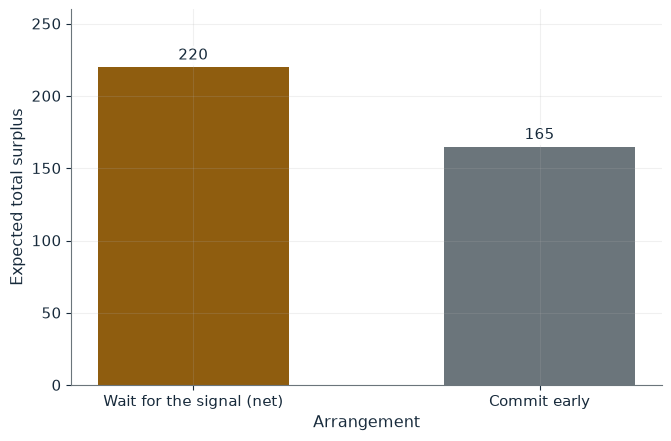

Waiting total        220
Waiting net of cost  220
Early total          165
Information loss     55
More surplus         waiting

Worked steps:
  1. Waiting = 110 + 110 = 220
  2. Net = 220 - 0 = 220
  3. Early pair = (110 + 55)/2 = 82.5
  4. Early = 82.5 + 82.5 = 165
  5. Information loss = 220 - 165 = 55

Waiting picks the high-fit pairs: 110 + 110 = 220, net 220 - 0 = 220. Early commitment fixes pairs worth (110 + 55)/2 = 82.5 each: 82.5 + 82.5 = 165. Waiting wins by 55.0. Waiting costs above 220 - 165 = 55 make early commitment efficient.


In [2]:
show(unravel_picture(w=0))

Change one input, `w`, and hold the others at the book's values:

In [3]:
sweep(unravel_picture, 'w', [0, 40, 70], {}, ['Waiting net of cost', 'Early total', 'More surplus'])

w | Waiting net of cost | Early total | More surplus
0 | 220 | 165 | waiting
40 | 180 | 165 | waiting
70 | 150 | 165 | early commitment


Early commitment loses 55 of information value. With a total waiting cost of 70, waiting nets 150 and early commitment (165) becomes efficient.

## 2. Boston-mechanism priority loss: when to hide your favorite

Nia values P at 120 and S at 85; Zara applies to P with probability $q$.

$$(1-0.40)(120)+0.40(0)=72 \qquad (1-0.20)(120)=96$$

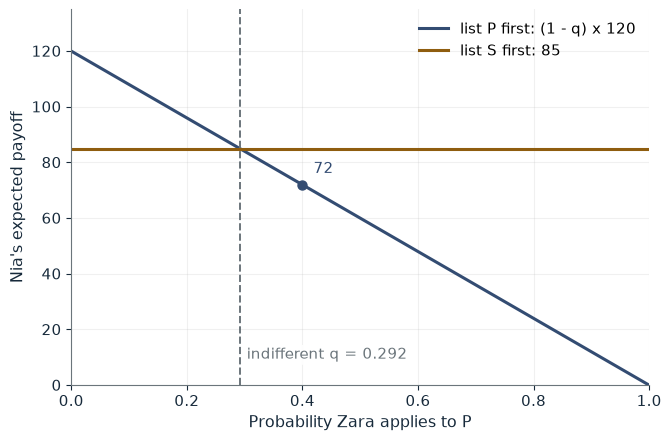

List P first              72
List S first              85
Best report               S first (demote favorite)
Indifference probability  0.292

Worked steps:
  1. P first = (1 - 0.40)(120) = 72
  2. S first = 85
  3. 72 < 85: S first (demote favorite)
  4. Indifference q = 1 - 85/120 = 0.292

Listing P first pays (1 - 0.40)(120) = 72; listing S first pays 85 for sure. Since 72 < 85, Nia's best report is S first (demote favorite). She is indifferent at q = 1 - 85/120 = 0.292.


In [4]:
show(boston_picture(q=0.4))

Change one input, `q`, and hold the others at the book's values:

In [5]:
sweep(boston_picture, 'q', [0.2, 0.3, 0.4, 0.6], {}, ['List P first', 'Best report'])

q | List P first | Best report
0.2 | 96 | P first (truthful)
0.3 | 84 | S first (demote favorite)
0.4 | 72 | S first (demote favorite)
0.6 | 48 | S first (demote favorite)


At q = 0.40 listing P first is worth 72 < 85, so Nia demotes her favorite; at 0.20 it is worth 96 and she ranks honestly. She is indifferent at q = 0.292.

## 3. Market thickness: pooled versus fragmented matching

Surpluses $v_{CA}=110$, $v_{CB}=65$, $v_{LA}=75$, $v_{LB}=95$.

$$110+95=205 \qquad 65+75=140 \qquad 35+30=65 \qquad 205-4(18)=133$$

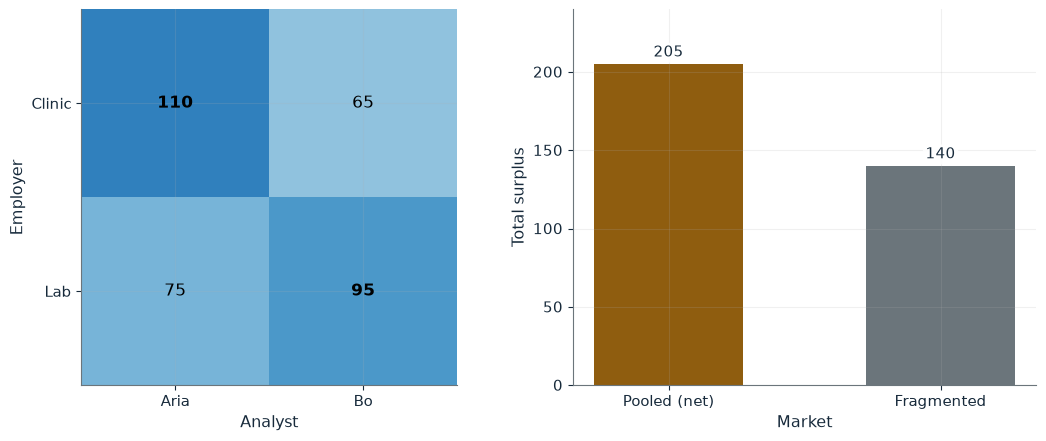

Pooled                 205
Pooled net of waiting  205
Fragmented             140
Pooling gain           65
Better market          pooling

Worked steps:
  1. Pooled = 110 + 95 = 205
  2. Net = 205 - 4(0) = 205
  3. Fragmented = 65 + 75 = 140
  4. Gain = 35 + 30 = 65

Pooled pairs Clinic with Aria and Lab with Bo: 110 + 95 = 205, net 205 - 4(0) = 205. Fragmented: 65 + 75 = 140. The gain 35 + 30 = 65 is the two option losses. Pooling wins by 65. Pooling stops paying above 65/4 = 16.25 per participant.


In [6]:
show(thick_picture(w=0))

Change one input, `w`, and hold the others at the book's values:

In [7]:
sweep(thick_picture, 'w', [0, 10, 18], {}, ['Pooled net of waiting', 'Fragmented', 'Better market'])

w | Pooled net of waiting | Fragmented | Better market
0 | 205 | 140 | pooling
10 | 165 | 140 | pooling
18 | 133 | 140 | fragmented


Pooling gains 65. A waiting cost of 18 per person cuts pooled surplus to 133, below 140; the breakeven is 65/4 = 16.25.

## 4. Market congestion: fewer applications, more reviews

120 graduates, 12 firms, capacity 40 per firm, two suitable firms per graduate.

$$120(12)=1{,}440, \qquad m_j=\frac{1{,}440}{12}=120$$

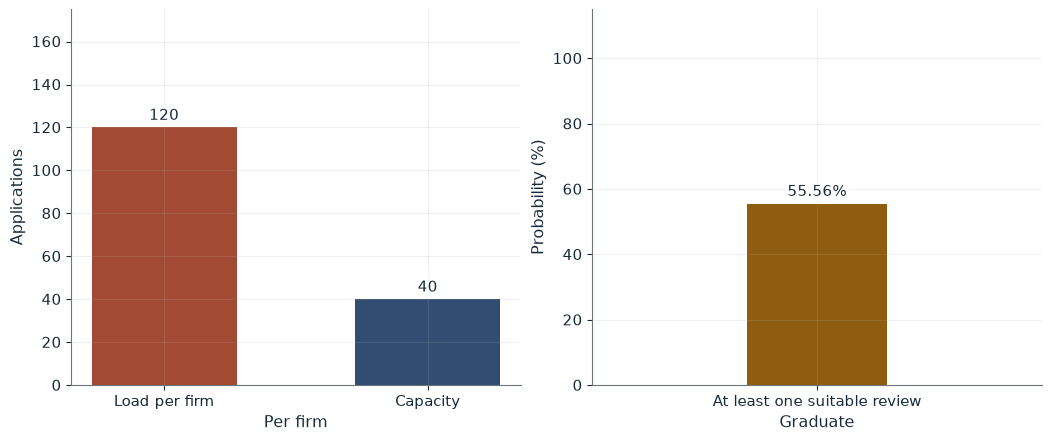

Total applications                  1,440
Load per firm                       120
Review probability                  0.3333
Unreviewed applications             960
P(a suitable application reviewed)  55.56%

Worked steps:
  1. Total = 120(12) = 1,440
  2. Load = 1,440/12 = 120
  3. rho = 40/120 = 0.3333
  4. Unreviewed = 1,440 - 480 = 960
  5. P = 1 - (1 - 40/120)^2 = 1 - (80/120)^2 = 55.56%

120(12) = 1,440 applications over 12 firms is 120 per firm. rho = 40/120 = 0.3333. Reviews: 480, leaving 960 unread. With two suitable firms, P = 1 - (1 - 40/120)^2 = 1 - (80/120)^2 = 55.56%.


In [8]:
show(congestion_picture(a=12, k=40))

Change one input, `a`, and hold the others at the book's values:

In [9]:
sweep(congestion_picture, 'a', [4, 8, 12], {'k': 40}, ['Load per firm', 'Review probability', 'P(a suitable application reviewed)'])

a | Load per firm | Review probability | P(a suitable application reviewed)
4 | 40 | 1.0000 | 100.00%
8 | 80 | 0.5000 | 75.00%
12 | 120 | 0.3333 | 55.56%


With 12 applications each, firms review a third of what they receive and a graduate has a 55.56% chance a suitable application is read. A cap of 4 brings load within capacity and the chance to 100%.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

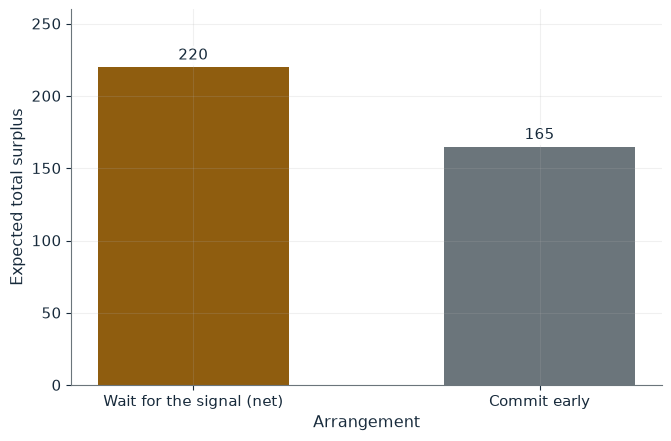

Waiting total        220
Waiting net of cost  220
Early total          165
Information loss     55
More surplus         waiting

Worked steps:
  1. Waiting = 110 + 110 = 220
  2. Net = 220 - 0 = 220
  3. Early pair = (110 + 55)/2 = 82.5
  4. Early = 82.5 + 82.5 = 165
  5. Information loss = 220 - 165 = 55

Waiting picks the high-fit pairs: 110 + 110 = 220, net 220 - 0 = 220. Early commitment fixes pairs worth (110 + 55)/2 = 82.5 each: 82.5 + 82.5 = 165. Waiting wins by 55.0. Waiting costs above 220 - 165 = 55 make early commitment efficient.


In [10]:
show(unravel_picture(w=0))

## Practice

**1.** With waiting cost 40, which arrangement yields more surplus?

<details><summary>Answer</summary>

220 - 40 = 180 > 165, so waiting; breakeven 55.

</details>

**2.** At q = 0.30, does Nia report truthfully?

<details><summary>Answer</summary>

0.7 x 120 = 84 < 85, so she still lists S first.

</details>

**3.** With 8 applications and K = 40, what is the chance a suitable application is reviewed?

<details><summary>Answer</summary>

Load 80 per firm, rho = 40/80 = 0.5, 1 - 0.5^2 = 75%.

</details>